# Port 80 DBSCAN/HDBSCAN Clustering

In [11]:
pip install polars pandas scikit-learn numpy matplotlib openai tqdm python-dotenv ollama jsonschema kneed umap-learn hdbscan


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Load & dataset

In [12]:
import polars as pl

df = pl.read_csv("results/sorted_enriched_port_80.csv")

df.describe()

statistic,id,expiration_id,src_ip,src_mac,src_oui,src_port,dst_ip,dst_mac,dst_oui,dst_port,protocol,ip_version,vlan_id,tunnel_id,bidirectional_first_seen_ms,bidirectional_last_seen_ms,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_first_seen_ms,src2dst_last_seen_ms,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_first_seen_ms,dst2src_last_seen_ms,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,…,src2dst_urg_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_urg_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,splt_direction,splt_ps,splt_piat_ms,application_name,application_category_name,application_is_guessed,application_confidence,requested_server_name,client_fingerprint,server_fingerprint,user_agent_x,content_type_x,uri,method,host,user_agent_y,status_code,status_msg,response_body_len,content_type_y,http_request_count,unique_uri_count,user_agent,content_type
str,f64,f64,str,str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str
"""count""",31117.0,31117.0,"""31117""","""31117""","""31117""",31117.0,"""31117""","""31117""","""31117""",31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,…,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,"""31117""","""31117""","""31117""","""31117""","""31117""",31117.0,31117.0,"""11346""","""1370""","""0""","""9329""","""10928""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""",31003.0,31003.0,"""2""","""2"""
"""null_count""",0.0,0.0,"""0""","""0""","""0""",0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""","""0""",0.0,0.0,"""19771""","""29747""","""31117""","""21788""","""20189""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""",114.0,114.0,"""31115""","""31115"""
"""mean""",3057.650223,0.000064,null,null,null,42515.613202,null,null,null,97.87306,6.0,4.0,0.0,0.0,1.7571e12,1.7571e12,7972.724074,9.761513,1243.325931,1.7571e12,1.7571e12,3406.68506,4.959829,502.378507,1.7341e12,1.7341e12,7505.296462,4.801684,740.947424,59.330237,93.974169,66.845755,265.611209,60.343381,77.733838,39.439142,…,0.0,3.386862,0.907671,0.61092,0.367291,1.739306,0.0,0.008645,0.0,4.769354,1.485008,0.033422,0.450397,null,null,null,null,null,0.552399,3.238005,null,null,null,null,null,null,null,null,null,null,null,null,null,0.579073,0.506016,null,null
"""std""",3391.48198,0.008017,null,null,null,13986.290554,null,null,null,851.967395,0.0,0.0,0.0,0.0,1.8321e9,1.8321e9,25020.322858,114.82777,19339.620244,1.8321e9,1.8321e9,22346.445956,58.064792,9853.450783,1.9989e11,1.9989e11,24546.553676,56.878851,9577.381297,5.93378,50.495587,89.948801,290.81467,9.48278,29.64573,64.273444,…,0.0,58.081534,29.574578,0.657861,0.532804,1.988116,0.0,0.145272,0.0,56.877798,29.993074,0.343958,0.609168,null,null,null,null,null,0.497255,2.486274,null,null,null,null,null,null,null,null,null,null,null,null,null,9.171454,2.902862,null,null
"""min""",0.0,0.0,"""1.15.173.165""","""bc:24:11:83:a7:6c""","""bc:24:11""",10.0,"""101.251.238.172""","""bc:24:11:83:a7:6c""","""bc:24:11""",80.0,6.0,4.0,0.0,0.0,1.7544e12,1.7544e12,0.0,1.0,54.0,1.7544e

In [13]:
port_freq = df["dst_port"].value_counts()
print(port_freq)

shape: (14, 2)
┌──────────┬───────┐
│ dst_port ┆ count │
│ ---      ┆ ---   │
│ i64      ┆ u32   │
╞══════════╪═══════╡
│ 20000    ┆ 2     │
│ 20014    ┆ 1     │
│ 52222    ┆ 1     │
│ 50336    ┆ 1     │
│ 20016    ┆ 2     │
│ …        ┆ …     │
│ 40496    ┆ 2     │
│ 46888    ┆ 1     │
│ 55972    ┆ 1     │
│ 57547    ┆ 1     │
│ 35422    ┆ 1     │
└──────────┴───────┘


Too much variance in ports, One hot encoding not worth it

In [14]:
import pandas as pd

if "application_confidence" in df.columns:
  df = df.with_columns(
    (pl.col("application_confidence") >= 4).cast(pl.Int8).alias("is_high_confidence")
  )
  df = df.drop("application_confidence")

if "tunnel_id" in df.columns:
  df = df.with_columns(
    pl.col("tunnel_id").cast(pl.Utf8)
  ).to_dummies(columns=["tunnel_id"])

columns_to_drop = [
  # Remove numeric identifiers
  'id', 'expiration_id',

  # Remove string identifiers
  'src_ip', 'dst_ip', 'src_mac', 'dst_mac', 'src_oui', 'dst_oui', 'src_port', 'dst_port',
  
  # Remove strings
  'application_name', 'application_category_name', 'client_fingerprint', 'server_fingerprint', 'requested_server_name', 
  'user_agent', 'content_type',

  # Remove features that may leak timestamp
  'bidirectional_first_seen_ms', 'bidirectional_last_seen_ms', 'src2dst_first_seen_ms', 'src2dst_last_seen_ms',
  'dst2src_first_seen_ms', 'dst2src_last_seen_ms','splt_direction', 'splt_ps', 'splt_piat_ms',

  # Remove added Zeek Feautures used to conduct DPI on the clusters after clustering is performed
  'user_agent_x','content_type_x','uri','method','host','user_agent_y','status_code',
  'status_msg','response_body_len','content_type_y','http_request_count','unique_uri_count'
]

df = df.drop([col for col in columns_to_drop if col in df.columns])

nunique_df = df.select(pl.all().n_unique())
constant_cols = [
  col for col, val in zip(nunique_df.columns, nunique_df.row(0))
  if val <= 1
]
df = df.drop(constant_cols)

print(f"Dropped {len(columns_to_drop)} string/list columns and {len(constant_cols)} constant columns")
df.head()

Dropped 38 string/list columns and 8 constant columns


bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,src2dst_max_ps,dst2src_min_ps,dst2src_mean_ps,dst2src_stddev_ps,dst2src_max_ps,bidirectional_min_piat_ms,bidirectional_mean_piat_ms,bidirectional_stddev_piat_ms,bidirectional_max_piat_ms,src2dst_min_piat_ms,src2dst_mean_piat_ms,src2dst_stddev_piat_ms,src2dst_max_piat_ms,dst2src_min_piat_ms,dst2src_mean_piat_ms,dst2src_stddev_piat_ms,dst2src_max_piat_ms,bidirectional_syn_packets,bidirectional_cwr_packets,bidirectional_ece_packets,bidirectional_ack_packets,bidirectional_psh_packets,bidirectional_rst_packets,bidirectional_fin_packets,src2dst_syn_packets,src2dst_cwr_packets,src2dst_ece_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_ece_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,application_is_guessed,is_high_confidence
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i8
119,3,170,119,2,112,0,1,58,54,56.666667,2.309401,58,54,56.0,2.828427,58,58,58.0,0.0,58,0,59.5,84.145707,119,119,119.0,0.0,119,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0
37,3,206,37,2,148,0,1,58,54,68.666667,22.030282,94,54,74.0,28.284271,94,58,58.0,0.0,58,0,18.5,26.162951,37,37,37.0,0.0,37,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,1
3801,13,1330,3801,7,713,3801,6,617,66,102.307692,76.738066,309,66,101.857143,91.390059,309,66,102.833333,64.107462,227,0,316.75,995.035141,3472,0,633.5,1391.931284,3472,0,760.2,1628.140258,3671,2,0,0,12,3,0,2,1,0,0,6,1,0,1,1,0,6,2,0,1,0,1
295,13,1277,295,6,618,295,7,659,54,98.230769,69.781987,273,66,103.0,83.364261,273,54,94.142857,62.493809,227,0,24.583333,49.271896,134,0,59.0,64.845971,135,0,49.166667,62.374407,134,2,0,0,10,4,2,1,1,0,0,5,2,0,0,1,0,5,2,2,1,0,1
158,3,166,158,2,108,0,1,58,54,55.333333,2.309401,58,54,54.0,0.0,54,58,58.0,0.0,58,0,79.0,111.722871,158,158,158.0,0.0,158,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0


Make sure the dataset does not contain NULL, NaNs or Infinete values

In [15]:
# Nulls
assert df.null_count().to_numpy().sum() == 0, "Null values detected"

# NaNs
assert df.select(pl.all().is_nan().sum()).to_numpy().sum() == 0, "NaNs detected"

# Infinite
assert df.select(pl.all().is_infinite().sum()).to_numpy().sum() == 0, "Infinite values detected"

print("No Null/NaNs/Infinite values found")

No Null/NaNs/Infinite values found


In [16]:
original_feature_names = df.columns
print(original_feature_names)

['bidirectional_duration_ms', 'bidirectional_packets', 'bidirectional_bytes', 'src2dst_duration_ms', 'src2dst_packets', 'src2dst_bytes', 'dst2src_duration_ms', 'dst2src_packets', 'dst2src_bytes', 'bidirectional_min_ps', 'bidirectional_mean_ps', 'bidirectional_stddev_ps', 'bidirectional_max_ps', 'src2dst_min_ps', 'src2dst_mean_ps', 'src2dst_stddev_ps', 'src2dst_max_ps', 'dst2src_min_ps', 'dst2src_mean_ps', 'dst2src_stddev_ps', 'dst2src_max_ps', 'bidirectional_min_piat_ms', 'bidirectional_mean_piat_ms', 'bidirectional_stddev_piat_ms', 'bidirectional_max_piat_ms', 'src2dst_min_piat_ms', 'src2dst_mean_piat_ms', 'src2dst_stddev_piat_ms', 'src2dst_max_piat_ms', 'dst2src_min_piat_ms', 'dst2src_mean_piat_ms', 'dst2src_stddev_piat_ms', 'dst2src_max_piat_ms', 'bidirectional_syn_packets', 'bidirectional_cwr_packets', 'bidirectional_ece_packets', 'bidirectional_ack_packets', 'bidirectional_psh_packets', 'bidirectional_rst_packets', 'bidirectional_fin_packets', 'src2dst_syn_packets', 'src2dst_cwr_p

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import numpy as np

# Numpy for df
X = df.to_numpy()

# # Scaler: was not scaling that well
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = np.clip(X_scaled, -5, 5)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(f"PCA Dimensions: {X_pca.shape[1]}")

PCA Dimensions: 55


Text(0.5, 1.0, 'Scree Plot')

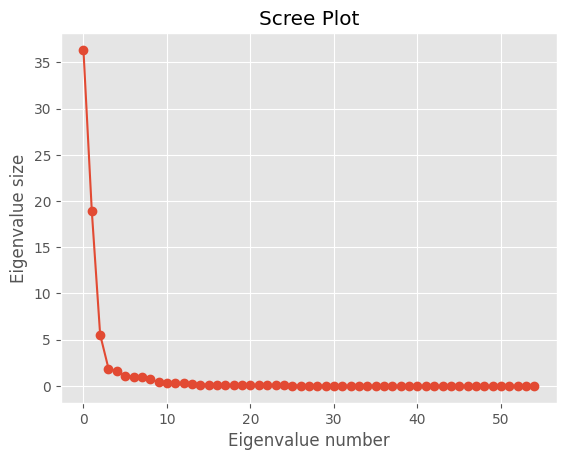

In [18]:
import matplotlib.pyplot as plt
plt.style.use("ggplot") 
plt.plot(pca.explained_variance_, marker='o')
plt.xlabel("Eigenvalue number")
plt.ylabel("Eigenvalue size")
plt.title("Scree Plot")

In [19]:
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.99) + 1
print(f"Components for 99% variance: {n_components}")

Components for 99% variance: 18


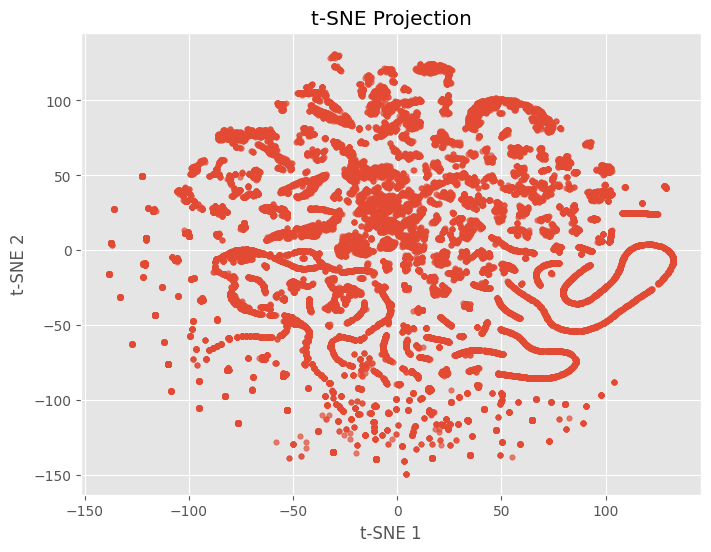

In [20]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import polars as pl
import numpy as np

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

projection = TSNE(
  n_components=2,
  perplexity=40,
  init="pca",
  learning_rate="auto",
  random_state=42,
).fit_transform(X_pca)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(
  projection[:, 0],
  projection[:, 1],
  s=15,
  alpha=0.7,
)
plt.title("t-SNE Projection")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

[Link to source for optimal hyperparameters DBSCAN](https://www.datacamp.com/tutorial/dbscan-clustering-algorithm?utm_cid=19589720821&utm_aid=157156374951&utm_campaign=230119_1-ps-other~dsa-tofu~all_2-b2c_3-emea_4-prc_5-na_6-na_7-le_8-pdsh-go_9-nb-e_10-na_11-na&utm_loc=9103947-&utm_mtd=-c&utm_kw=&utm_source=google&utm_medium=paid_search&utm_content=ps-other~emea-en~dsa~tofu~tutorial~machine-learning&gad_source=1&gad_campaignid=19589720821&gbraid=0AAAAADQ9WsFcsoU6viY__K-SLCYqgJGS4&gclid=EAIaIQobChMI9au7_OmSlAMV-7KDBx1TADZ4EAAYASAAEgLCwvD_BwE)

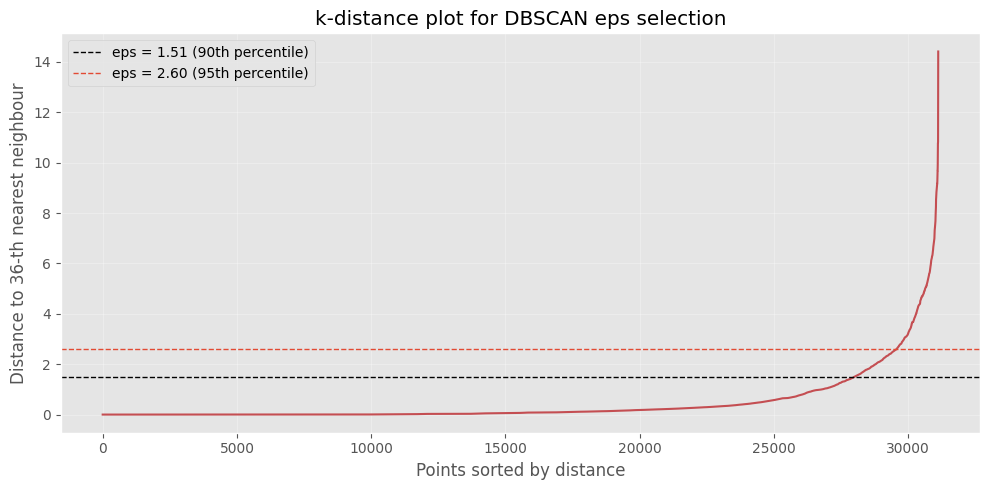

In [21]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt
import os

# k = 2 × n_features (rule of thumb for DBSCAN min_samples)
min_samples = X_pca.shape[1] * 2

nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances, _ = nbrs.kneighbors(X_pca)
k_distances = np.sort(distances[:, -1])

p90 = np.percentile(k_distances, 90)
p95 = np.percentile(k_distances, 95)

os.makedirs('figures/80_(h)dbscan', exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_distances, color='#c44e52', linewidth=1.5)
ax.axhline(p90, color='#000000', linestyle='--', linewidth=1,label=f'eps = {p90:.2f} (90th percentile)')
ax.axhline(p95, linestyle='--', linewidth=1,label=f'eps = {p95:.2f} (95th percentile)')
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to {min_samples}-th nearest neighbour")
ax.set_title("k-distance plot for DBSCAN eps selection")
ax.legend(loc='upper left', frameon=True)
ax.grid(alpha=0.3)

plt.savefig('figures/80_(h)dbscan/dbscan_eps_selection.png', dpi=150)
plt.tight_layout()
plt.show()

Min Samples: 36
Clusters found: 36
Amount of Noise: 2545 (8.18%)


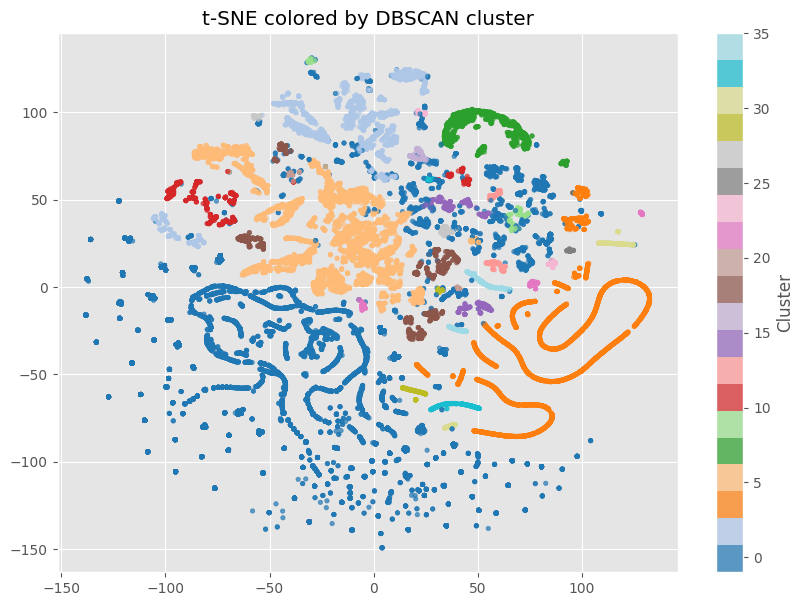

In [22]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

eps = np.percentile(k_distances, 90)

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
clusters = dbscan.fit_predict(X_pca)

n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"Min Samples: {min_samples}")
print(f"Clusters found: {n_clusters}")
print(f"Amount of Noise: {n_noise} ({ (n_noise/len(clusters))*100 :.2f}%)")

plt.figure(figsize=(10, 7))
plt.scatter(projection[:, 0], projection[:, 1], c=clusters, cmap='tab20', s=10, alpha=0.7)
plt.colorbar(label='Cluster')
plt.title("t-SNE colored by DBSCAN cluster")
plt.savefig('figures/80_(h)dbscan/dbscan_tsn.png', dpi=150)
plt.show()

HDBSCAN better fit for the differences in density regions

### Compare diffrerent strategies

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


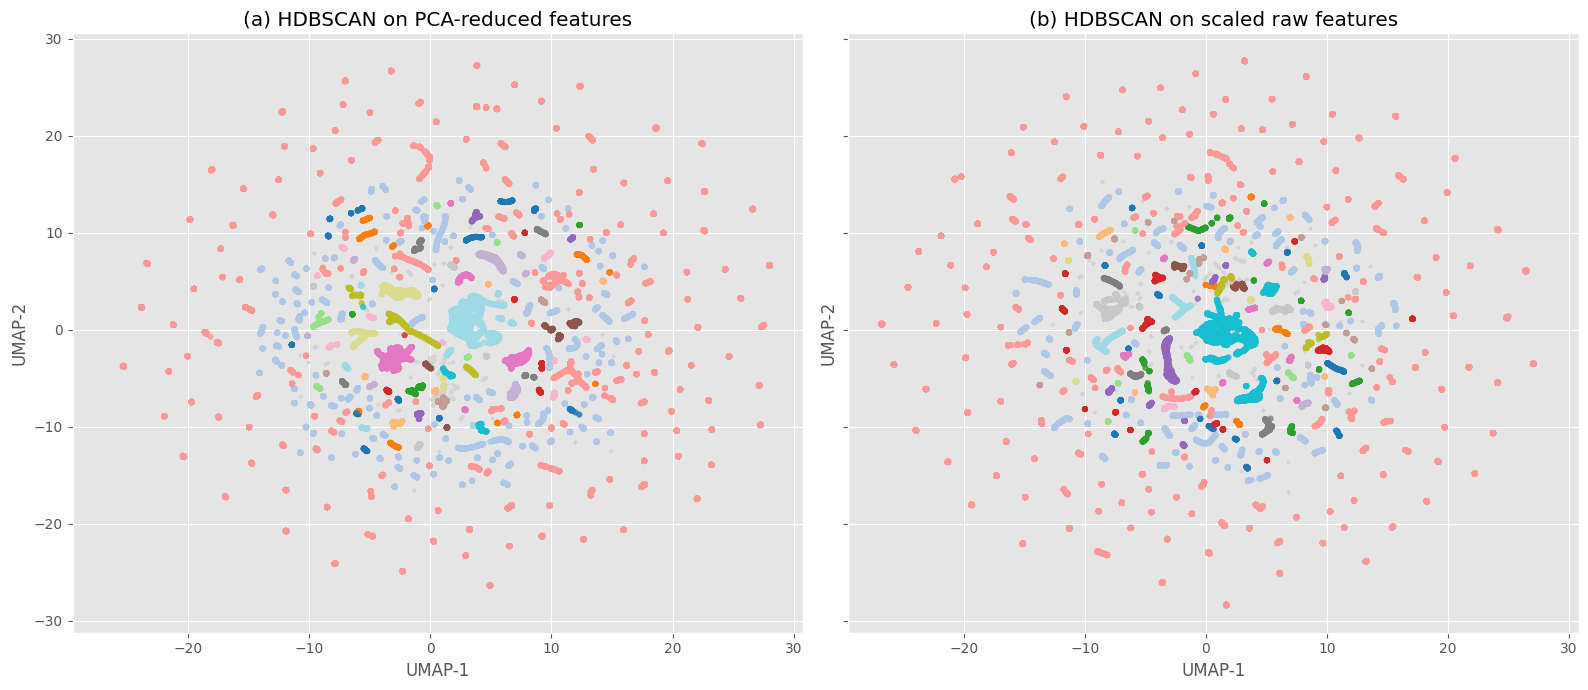

In [23]:
import umap
import hdbscan

clusterer = hdbscan.HDBSCAN(
  min_cluster_size=100,
  min_samples=20,
  cluster_selection_epsilon=1.0,
  cluster_selection_method='leaf'
)
hdb_clusters_pca = clusterer.fit_predict(X_pca)
hdb_clusters_scaled = clusterer.fit_predict(X_scaled)

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
projection_pca = reducer.fit_transform(X_pca)
projection_scaled = reducer.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

for ax, (clusters, proj, title) in zip(axes, [
  (hdb_clusters_pca, projection_pca, "(a) HDBSCAN on PCA-reduced features"),
  (hdb_clusters_scaled, projection_scaled, "(b) HDBSCAN on scaled raw features"),
]):
  mask = clusters != -1
  ax.scatter(proj[~mask, 0], proj[~mask, 1], c='lightgrey', s=3, alpha=0.2)
  ax.scatter(proj[mask, 0], proj[mask, 1], c=clusters[mask], cmap='tab20', s=15, alpha=0.8)
  ax.set_title(title)
  ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")

plt.savefig('figures/80_(h)dbscan/hdbscan_scaled_vs_pca.png', dpi=150)
plt.tight_layout()

### Compare different hyperparameters

In [40]:
import hdbscan
import pandas as pd

results = []
for mcs in [50, 100, 200, 400]:
  for ms in [10, 20, 50]:
    for eps in [0.0, 0.5, 1.0, 1.5]:
      for method in ['eom', 'leaf']:
        labels = hdbscan.HDBSCAN(
          min_cluster_size=mcs,
          min_samples=ms,
          cluster_selection_epsilon=eps,
          cluster_selection_method=method,
        ).fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        largest = pd.Series(labels[labels != -1]).value_counts().iloc[0] \
          if n_clusters > 0 else 0
        results.append({
          'min_cluster_size': mcs,
          'min_samples': ms,
          'eps': eps,
          'method': method,
          'n_clusters': n_clusters,
          'noise_%': round(noise_pct, 1),
          'largest_cluster': largest,
        })

df_grid = pd.DataFrame(results)
print(df_grid.to_string(index=False))

 min_cluster_size  min_samples  eps method  n_clusters  noise_%  largest_cluster
               50           10  0.0    eom         166     13.5             1916
               50           10  0.0   leaf         220     24.0              562
               50           10  0.5    eom          75      7.4             9311
               50           10  0.5   leaf          77      7.8             9311
               50           10  1.0    eom          60      6.4            10644
               50           10  1.0   leaf          60      6.4            10644
               50           10  1.5    eom          37      4.6            11398
               50           10  1.5   leaf          37      4.6            11398
               50           20  0.0    eom         151     15.0             2646
               50           20  0.0   leaf         196     29.3              493
               50           20  0.5    eom          72      8.7             9096
               50           

In [41]:
import hdbscan

clusterer_100 = hdbscan.HDBSCAN( min_cluster_size=100, min_samples=20, cluster_selection_epsilon=1.0, cluster_selection_method='leaf')
hdb_clusters_100 = clusterer_100.fit_predict(X_pca)

clusterer_200 = hdbscan.HDBSCAN( min_cluster_size=200, min_samples=20, cluster_selection_epsilon=1.0, cluster_selection_method='leaf')
hdb_clusters_200 = clusterer_200.fit_predict(X_pca)


In [42]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

def evaluate_multi_seed(X, labels, name, n_seeds=8, sample_size=20000):
  sils, dbs = [], []
  for seed in range(n_seeds):
    rng = np.random.default_rng(seed)
    sample_idx = rng.choice(len(X), min(sample_size, len(X)), replace=False)
    X_sample, labels_sample = X[sample_idx], labels[sample_idx]
    mask = labels_sample != -1
    sils.append(silhouette_score(X_sample[mask], labels_sample[mask]))
    dbs.append(davies_bouldin_score(X_sample[mask], labels_sample[mask]))
  
  sils, dbs = np.array(sils), np.array(dbs)
  n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
  noise_pct = (labels == -1).mean() * 100
  print(f"{name}")
  print(f"Clusters: {n_clusters}")
  print(f"Noise: {noise_pct:.1f}%")
  print(f"Silhouette: {sils.mean():.4f}")
  print(f"Davies-Bouldin: {dbs.mean():.4f}")

evaluate_multi_seed(X_pca, hdb_clusters_200, "mcs=200")
evaluate_multi_seed(X_pca, hdb_clusters_100, "mcs=100")

mcs=200
Clusters: 20
Noise: 10.7%
Silhouette: 0.4712
Davies-Bouldin: 0.8565
mcs=100
Clusters: 43
Noise: 8.6%
Silhouette: 0.4792
Davies-Bouldin: 0.7050


In [43]:
clusterer_150 = hdbscan.HDBSCAN(min_cluster_size=150, min_samples=20,cluster_selection_epsilon=1.0, cluster_selection_method='leaf')
hdb_clusters_150 = clusterer_150.fit_predict(X_pca)
evaluate_multi_seed(X_pca, hdb_clusters_150, "mcs=150")


mcs=150
Clusters: 29
Noise: 9.7%
Silhouette: 0.4882
Davies-Bouldin: 0.7847


### BEST RUN min_cluster_size=150, min_samples=20,cluster_selection_epsilon=1.0

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


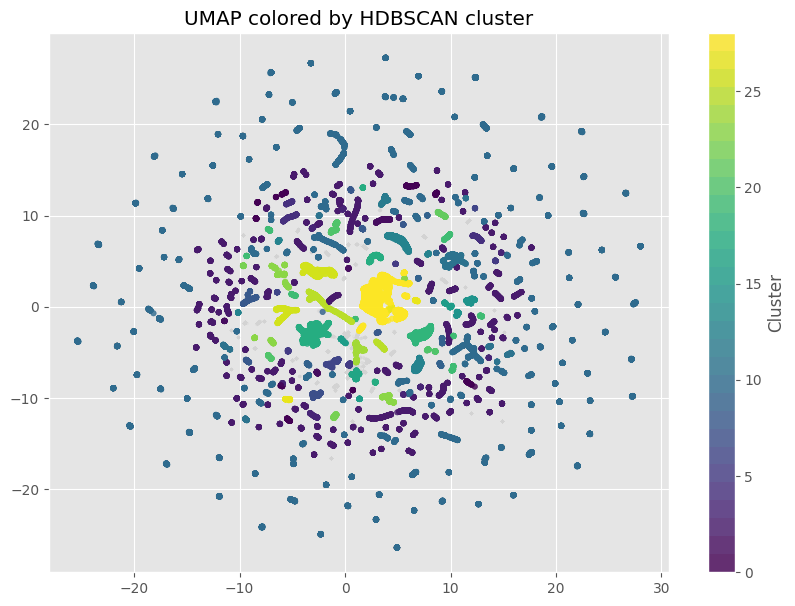

In [44]:
import umap

clusterer = hdbscan.HDBSCAN(
  min_cluster_size=150,
  min_samples=20,
  cluster_selection_epsilon=1.0,
  cluster_selection_method='leaf'
)
hdb_clusters = clusterer.fit_predict(X_pca)

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
projection = reducer.fit_transform(X_pca)

cmap_30 = plt.get_cmap('viridis').resampled(30)

mask = hdb_clusters != -1
plt.figure(figsize=(10, 7))
plt.scatter(projection[~mask, 0], projection[~mask, 1], c='lightgrey', s=3, alpha=0.2, label='noise')
plt.scatter(projection[mask, 0], projection[mask, 1], c=hdb_clusters[mask], cmap=cmap_30, s=15, alpha=0.8)
plt.colorbar(label='Cluster')
plt.title("UMAP colored by HDBSCAN cluster")
plt.savefig('figures/80_(h)dbscan/hdbscan_umap.png', dpi=150)
plt.show()

#### Overview (Check cluster_representatives/ better)

In [45]:
import ast
df_full = pd.read_csv("results/sorted_enriched_port_80.csv", low_memory=False)
df_full["cluster"] = hdb_clusters
uri_flows = df_full[df_full["uri"].notna()]

http_clusters = uri_flows["cluster"].value_counts().index.tolist()

for c in sorted(http_clusters):
  subset = df_full[df_full["cluster"] == c]
  all_uris, all_codes = [], []
  for v in subset["uri"].dropna():
    try: all_uris.extend(ast.literal_eval(v))
    except: pass
  for v in subset["status_code"].dropna():
    try: all_codes.extend(ast.literal_eval(v))
    except: pass

  stats = subset[['bidirectional_packets','bidirectional_bytes','bidirectional_duration_ms','bidirectional_syn_packets',
    'bidirectional_rst_packets','bidirectional_fin_packets']].mean().round(2)

  print(f"\nCluster {c} ({len(subset)} flows)")
  print(f"URIs: {pd.Series(all_uris).value_counts().to_dict()}")
  print(f"Codes: {pd.Series(all_codes).value_counts().head(3).to_dict()}")
  print(f"pkts={stats['bidirectional_packets']} "
    f"bytes={stats['bidirectional_bytes']} "
    f"dur={stats['bidirectional_duration_ms']}ms "
    f"syn={stats['bidirectional_syn_packets']} "
    f"rst={stats['bidirectional_rst_packets']} "
    f"fin={stats['bidirectional_fin_packets']}")


Cluster -1 (3003 flows)
URIs: {'/login': 1532, '/': 738, '/cgi-bin/luci/;stok=/locale': 85, '/favicon.ico': 59, '/containers/json': 43, 'www.google.com:443': 43, '/Login.html': 39, '/.env': 39, '/cgi-bin/../../../../../../../../../../bin/sh': 36, '/cgi-bin/2e2e/2e2e/2e2e/2e2e/2e2e/2e2e/2e2e/bin/sh': 34, '*': 34, '/hello.world?\\xadd+allow_url_include=1+\\xadd+auto_prepend_file=php://input': 33, '/vendor/phpunit/phpunit/src/Util/PHP/eval-stdin.php': 33, '/vendor/phpunit/phpunit/Util/PHP/eval-stdin.php': 33, '/vendor/phpunit/src/Util/PHP/eval-stdin.php': 33, '/vendor/phpunit/Util/PHP/eval-stdin.php': 33, '/vendor/phpunit/phpunit/LICENSE/eval-stdin.php': 33, '/vendor/vendor/phpunit/phpunit/src/Util/PHP/eval-stdin.php': 33, '/phpunit/phpunit/src/Util/PHP/eval-stdin.php': 33, '/phpunit/phpunit/Util/PHP/eval-stdin.php': 33, '/phpunit/src/Util/PHP/eval-stdin.php': 33, '/phpunit/Util/PHP/eval-stdin.php': 33, '/lib/phpunit/phpunit/src/Util/PHP/eval-stdin.php': 33, '/lib/phpunit/phpunit/Util/PH

### Overiview of how each feature impacts each cluster

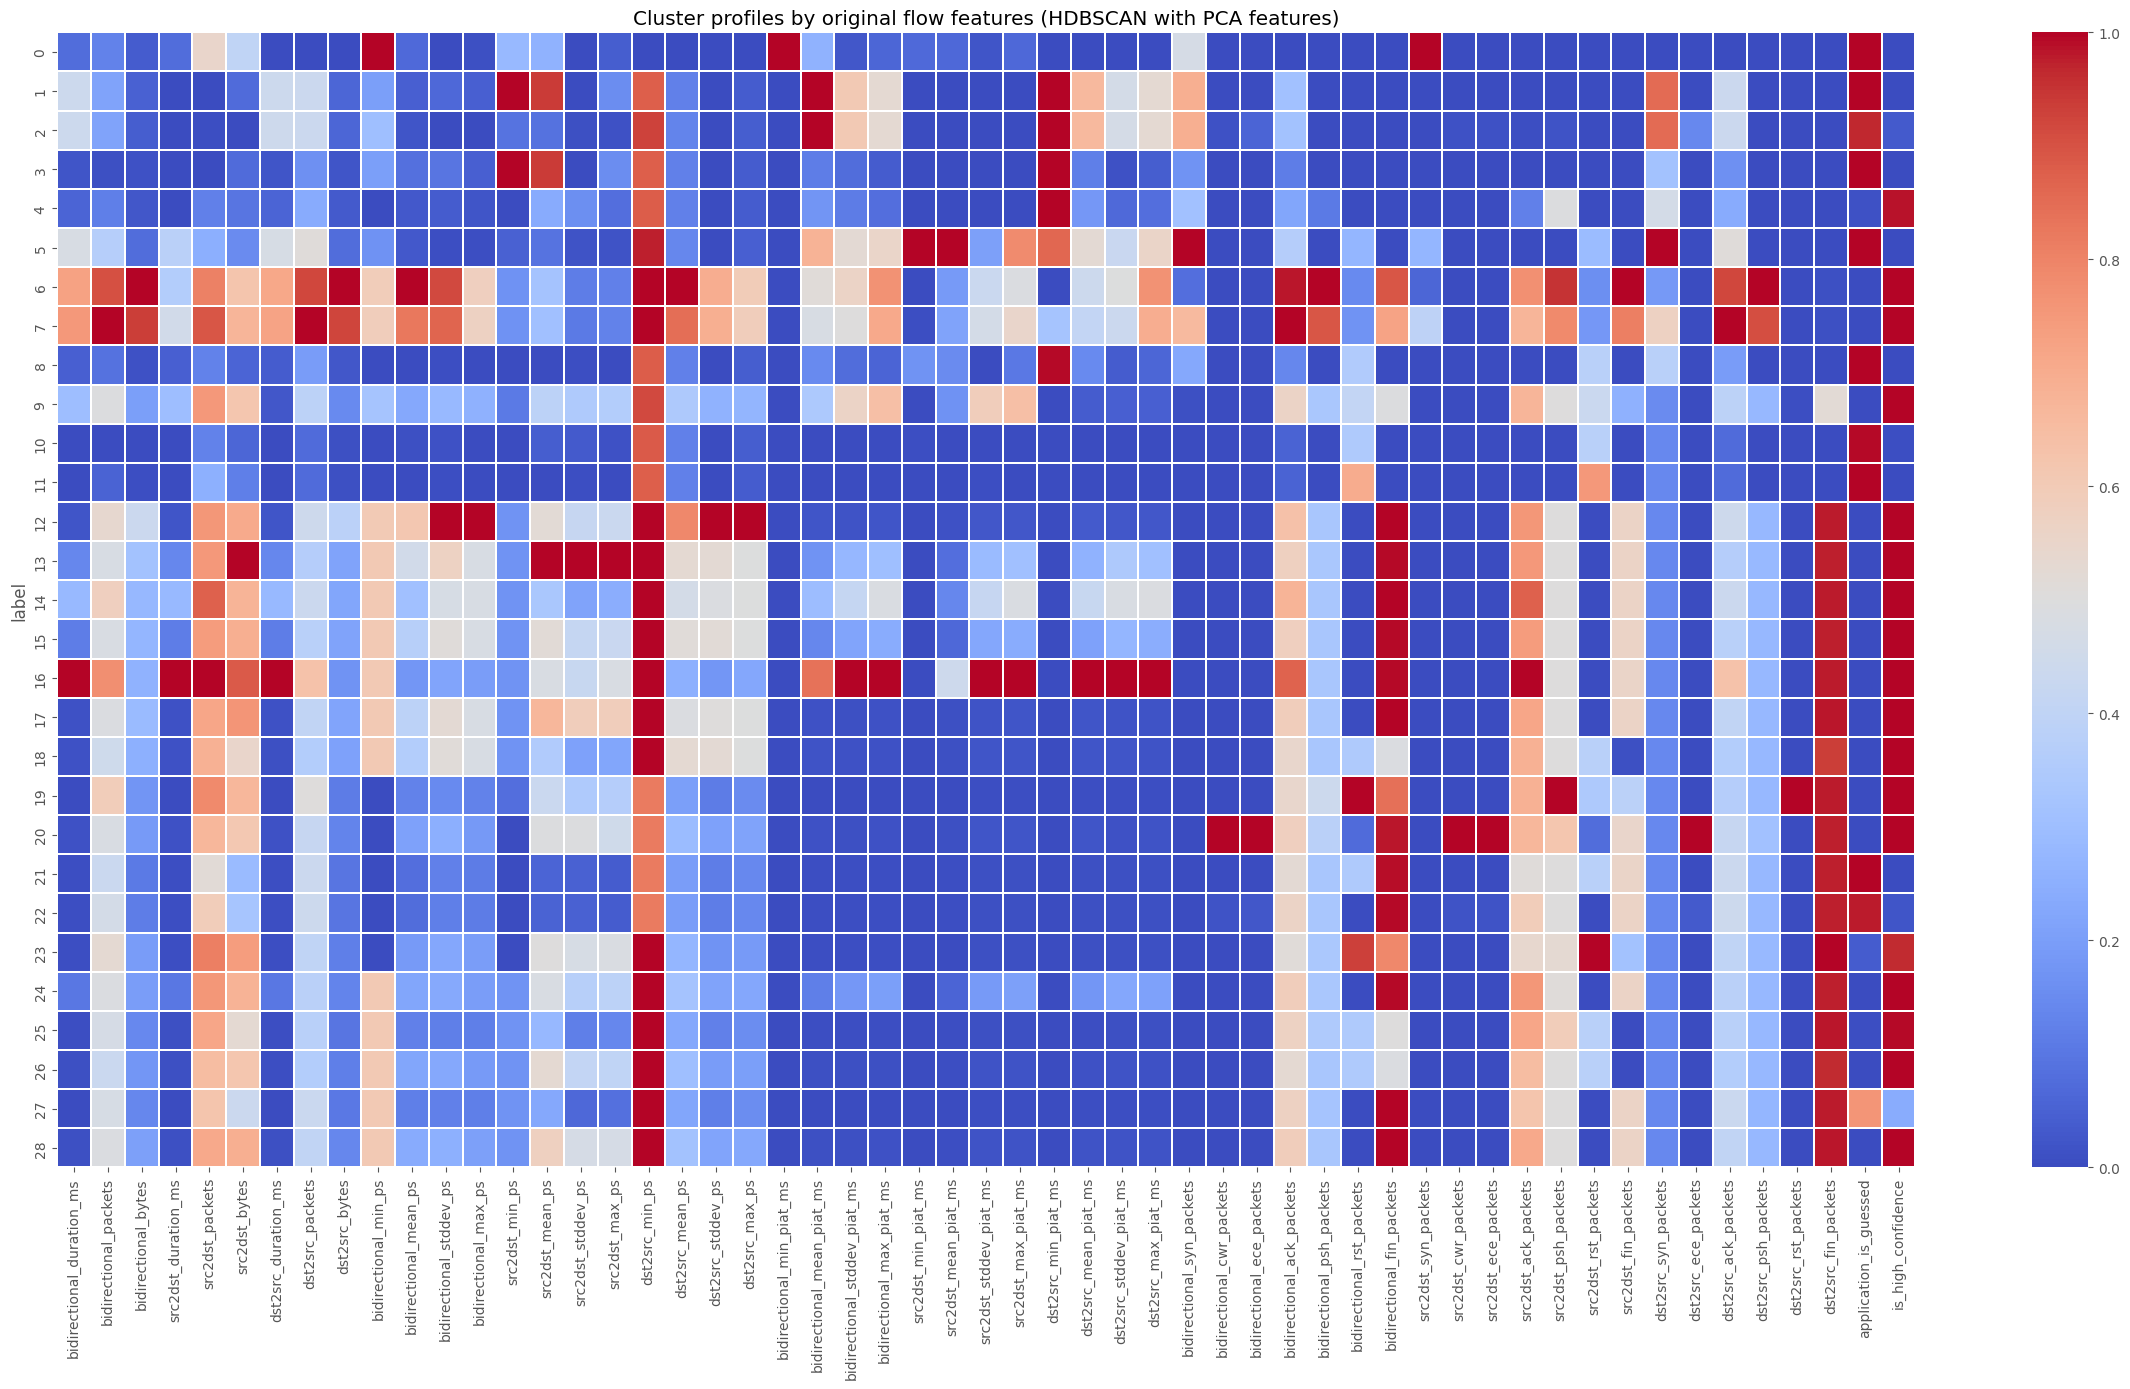

In [46]:
import seaborn as sns

df_original = pd.DataFrame(X, columns=original_feature_names)
df_original["cluster"] = hdb_clusters

# Exclude noise for heatmap
df_clean = df_original[df_original["cluster"] != -1].copy()
df_clean["label"] = df_clean["cluster"]

cluster_means = df_clean.groupby("label")[original_feature_names].mean()
normalized = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

plt.figure(figsize=(24, 14))
sns.heatmap(normalized, annot=False, cmap='coolwarm', linewidths=0.3)
plt.title('Cluster profiles by original flow features (HDBSCAN with PCA features)')
plt.tight_layout()
plt.savefig('figures/80_(h)dbscan/hdbscan_feature_map.png', dpi=150)
plt.show()

In [47]:
# Print top distinguishing features per cluster

cluster_means = df_original.groupby('cluster').mean()

feature_variance = cluster_means.var().sort_values(ascending=False)

# Normalize before taking variance so scale doesn't dominate
normalized_means = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())
feature_variance_normalized = normalized_means.var().sort_values(ascending=False)

top_features = feature_variance_normalized.index.tolist()

for c in sorted(df_original["cluster"].unique()):
  if c == -1:
    continue
  subset = df_original[df_original["cluster"] == c]
  print(f"\nCluster {c} ({len(subset)} flows)")
  print(subset[top_features].mean().sort_values(ascending=False).head(5).to_string())


Cluster 0 (360 flows)
src2dst_duration_ms          5468.230556
bidirectional_duration_ms    5468.230556
bidirectional_max_piat_ms    1975.005556
src2dst_max_piat_ms          1975.005556
src2dst_mean_piat_ms         1388.433234

Cluster 1 (199 flows)
bidirectional_duration_ms    31708.693467
dst2src_duration_ms          31708.582915
bidirectional_max_piat_ms    16344.085427
dst2src_max_piat_ms          16344.085427
dst2src_mean_piat_ms          6345.630402

Cluster 2 (3716 flows)
bidirectional_duration_ms    31777.617330
dst2src_duration_ms          31777.508073
dst2src_max_piat_ms          16381.810818
bidirectional_max_piat_ms    16381.810818
dst2src_mean_piat_ms          6355.708517

Cluster 3 (188 flows)
bidirectional_duration_ms    1523.106383
dst2src_duration_ms          1522.994681
bidirectional_max_piat_ms    1275.680851
dst2src_max_piat_ms          1275.680851
dst2src_mean_piat_ms         1151.413121

Cluster 4 (325 flows)
bidirectional_duration_ms    4046.935385
dst2src_durat

In [48]:
# For each cluster, show what makes it DIFFERENT from the rest
baseline = df_original[df_original["cluster"] != -1].mean()

for c in sorted(df_original["cluster"].unique()):
  if c == -1:
    continue
  subset = df_original[df_original["cluster"] == c]
  # Ratio: distinctive high, low = distinctive low
  ratio = (subset.mean() / (baseline + 1e-9)).sort_values(ascending=False)
  
  print(f"\nCluster {c} ({len(subset)} flows)")
  print("HIGH:", ratio.head(4).index.tolist())
  print("LOW:", ratio.tail(4).index.tolist())


Cluster 0 (360 flows)
HIGH: ['bidirectional_min_piat_ms', 'src2dst_min_piat_ms', 'src2dst_syn_packets', 'src2dst_mean_piat_ms']
LOW: ['dst2src_min_piat_ms', 'dst2src_max_ps', 'src2dst_stddev_ps', 'cluster']

Cluster 1 (199 flows)
HIGH: ['dst2src_min_piat_ms', 'bidirectional_mean_piat_ms', 'dst2src_mean_piat_ms', 'dst2src_duration_ms']
LOW: ['src2dst_min_piat_ms', 'bidirectional_ece_packets', 'bidirectional_cwr_packets', 'src2dst_max_piat_ms']

Cluster 2 (3716 flows)
HIGH: ['dst2src_min_piat_ms', 'bidirectional_mean_piat_ms', 'dst2src_mean_piat_ms', 'dst2src_duration_ms']
LOW: ['src2dst_mean_piat_ms', 'bidirectional_fin_packets', 'bidirectional_rst_packets', 'src2dst_max_piat_ms']

Cluster 3 (188 flows)
HIGH: ['dst2src_min_piat_ms', 'src2dst_min_ps', 'application_is_guessed', 'src2dst_mean_ps']
LOW: ['bidirectional_ece_packets', 'bidirectional_cwr_packets', 'src2dst_mean_piat_ms', 'src2dst_max_piat_ms']

Cluster 4 (325 flows)
HIGH: ['dst2src_min_piat_ms', 'is_high_confidence', 'src2dst

In [49]:
import numpy as np
import os

df_full["cluster_probability"] = clusterer.probabilities_

os.makedirs("clusters/clusters_80_hdbscan", exist_ok=True)

cluster_sizes = df_full["cluster"].value_counts().to_dict()

for cluster_id in sorted(df_full["cluster"].unique()):
  if cluster_id == -1:
    continue
  subset_idx = df_full.index[df_full["cluster"] == cluster_id].to_numpy()
  # Most representative by HDBSCAN probability
  representative_idx = (df_full.loc[subset_idx].sort_values("cluster_probability", ascending=False).head(40).index)
  # Furthest away / most anomalous by lowest HDBSCAN probability
  anomalous_idx = (df_full.loc[subset_idx].sort_values("cluster_probability", ascending=True).head(30).index)
  
  df_full.loc[representative_idx].to_csv(f"clusters/clusters_80_hdbscan/{cluster_id:02d}_representative.csv",index=False)
  df_full.loc[anomalous_idx].to_csv(f"clusters/clusters_80_hdbscan/{cluster_id:02d}_anomalous.csv",index=False)
  print(f"Saved cluster {cluster_id} ({cluster_sizes[cluster_id]} flows)")

Saved cluster 0 (360 flows)
Saved cluster 1 (199 flows)
Saved cluster 2 (3716 flows)
Saved cluster 3 (188 flows)
Saved cluster 4 (325 flows)
Saved cluster 5 (152 flows)
Saved cluster 6 (268 flows)
Saved cluster 7 (172 flows)
Saved cluster 8 (415 flows)
Saved cluster 9 (281 flows)
Saved cluster 10 (10707 flows)
Saved cluster 11 (648 flows)
Saved cluster 12 (161 flows)
Saved cluster 13 (1056 flows)
Saved cluster 14 (306 flows)
Saved cluster 15 (189 flows)
Saved cluster 16 (170 flows)
Saved cluster 17 (1403 flows)
Saved cluster 18 (557 flows)
Saved cluster 19 (317 flows)
Saved cluster 20 (377 flows)
Saved cluster 21 (191 flows)
Saved cluster 22 (202 flows)
Saved cluster 23 (595 flows)
Saved cluster 24 (286 flows)
Saved cluster 25 (662 flows)
Saved cluster 26 (1108 flows)
Saved cluster 27 (175 flows)
Saved cluster 28 (2928 flows)


### Family based in the inspected clusters

In [ ]:
cluster_families = {
  -1: "anomalous",
  0: "honeynet_outbound", # src=9.1.10.10, 7 SYNs only, never answered
  1: "syn_stall", # single src, SYN-ACK pattern, 31s timeout
  2: "syn_stall", # diverse srcs, same SYN-ACK pattern
  3: "syn_stall", # brief variant (3 pkts, 1s)
  4: "host_get_probe", # GET / with Host youtube.com 
  5: "syn_stall", # SYN-ACK pattern 9 pkts, 1 RST, 21s
  6: "successful_root_fetch", # GET / returning 200 with 7KB, 71s slow PIAT. is_guessed=0, real HTTP confirmed.
  7: "successful_root_fetch", # 57s PIAT, with handshake retries
  8: "syn_scan_rst", # client never completes handshake, sends RST
  9: "device_fingerprint_probe", # 51/70 from 185.93.89.97, related to Palo Alto scanner. 
  10: "syn_scan_rst", # client never completes handshake, sends RST, anomalies realated to freedomhouse.org
  11: "syn_scan_rst", # client never completes handshake, sends double RST
  12: "device_fingerprint_probe", # Censys: /Login.html + /image/favicon.ico
  13: "successful_root_fetch", # Mozilla/5.0 (compatible; CensysInspect/1.1) or  (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/90.0.4430.85 Safari/537.36 Edg/90.0.818.46
  14: "successful_root_fetch", # 20s
  15: "successful_root_fetch", # 7s Mozilla/5.0 (compatible; InternetMeasurement/1.0)
  16: "env_git_hunter", # dominated src 185.201.188.37 with .env paths, really few mysqladmin grab attempts
  17: "successful_root_fetch", # 1s real browsers iPhone/Chrome/Firefox
  18: "leakix_scan", # l9tcpid/v1.1.0  HTTP banner grab, search engine for exposed services and misconfigurations (similar in concept to Shodan/Censys)
  19: "protocol_preface_probe", # TLS handshake 400 RST
  20: "broad_recon",# GET  fingerprinting /geoserver/, /RDWeb/, /api/sonicos/, /.env, /favicon.ico, /wp-content/
                    # PLUS CONNECT HTTP_Connect.Naver, HTTP_Connect.Google, HTTP_Connect
  21: "malformed_400_rst", # src 211.59.174.163 dominated, 400 + RST + FIN
  22: "malformed_400_rst", # src 211.59.174.163 dominated,, 400 without RST
  23: "router_iot_exploit", # /cgi-bin/luci/;stok=/locale, /boaform/admin/formLogin, /device.rsp?…boatnet.arm7
  24: "enterprise_app_sweep", # /manager/html, /actuator/health, /developmentserver/...
  25: "protocol_preface_probe", # GET /+ PRI * HTTP/2.0 preface
  26: "broad_recon", # l9explore dominated recon: /robots.txt, /sitemap.xml, /.well-known/security.txt, /favicon.ico, TLS 400 too
  27: "malformed_400_rst", # 400 fast
  28: "broad_recon", # /.env, /.git/config, /api/.env, /actuator/gateway/routes
}

anomalous: Low-density patterns not captured by HDBSCAN; includes credential stuffing, Log4Shell, multi-exploit kits(EXPLORED UNDER RESULTS)

honeypot_outbound: Outbound flows originating from the honeypot itself

syn_stall: TCP handshake initiated but unanswered

fast_tcp_probe: Short lived TCP probes (SYN+RST or SYN only, low duration); port scanning behavior

successful_root_fetch: GET / returning 200; varies in duration and sources

device_fingerprint_probe: Device identification probes (/Login.html + /image/favicon.ico)

env_git_hunter: Scanners hunting for exposed .env, .git/config, and config files

router_iot_exploit: Active exploitation against IoT/router endpoints (/GponForm/diag_Form?images/, /cgi-bin/system_mgr.cgi?, /goform/SystemCommand)

enterprise_app_sweep: Multi-target enterprise software fingerprinting (tomcat: /manager/html, /boaform/admin/formLogin?username=user&psd=user, springboot: /actuator/health)

connect: HTTP CONNECT probes (targeting ipv4.jsonip.com, ipinfo.io, naver.com, etc.)

malformed_400_rst: Server-side HTTP 400 responses closed with RST; includes TLS on port 80 mismatche and other protocolerrors

protocol_preface_probe: Protocol fingerprinting probes: TLS handshakes and HTTP/2 PRI prefaces sent to a port 80 HTTP server